# Problema Gravitacional de N-Cuerpos y Estabilidad Orbital

**Presentado por:** Eduardo Pérez Cárdenas

## Fase I: Fundamentos Matemáticos y Diferenciación Numérica

Para modelar la evolución de un sistema de N-Cuerpos, la dinámica dicta que la aceleración de cualquier cuerpo $i$ es la suma vectorial de los gradientes gravitacionales producidos por todos los demás cuerpos $j$:
$$ \frac{d^2\vec{r}_i}{dt^2} = - \sum_{j \neq i}^{N} G m_j \frac{\vec{r}_i - \vec{r}_j}{|\vec{r}_i - \vec{r}_j|^3} $$

### Respuesta Pregunta 1: Deducción de la Diferenciación de Lagrange (Ec. 0.3)
Para aproximar estas derivadas computacionalmente, partimos del polinomio de interpolación de Lagrange:
$$ f(x) \approx \sum_{j=0}^{n} l_j(x) f_j \quad \text{donde} \quad l_j(x) = \frac{\pi(x)}{(x - x_j)\pi'(x_j)} $$

Definimos $\pi(x) = \prod_{i=0}^n (x - x_i)$. Derivando la aproximación polinómica respecto a $x$, obtenemos:
$$ f'(x) \approx \sum_{j=0}^{n} l'_j(x) f_j $$

Aplicando la regla del cociente, la derivada del polinomio base $l_j(x)$ es:
$$ l'_j(x) = \frac{\pi'(x)(x - x_j) - \pi(x)}{(x - x_j)^2 \pi'(x_j)} $$

Para una malla de puntos uniformemente espaciados con un tamaño de paso $h$, introducimos el cambio de variable $x = x_0 + sh$. Esto implica que $dx = h \, ds$ y, por la regla de la cadena, el operador diferencial se transforma en $\frac{d}{dx} = \frac{1}{h}\frac{d}{ds}$.

La distancia entre los nodos espaciados de la malla se expresa como $x_j - x_i = (j - i)h$. Al evaluar analíticamente el denominador $\pi'(x_j)$, obtenemos la constante discreta:
$$ \pi'(x_j) = \prod_{i=0, i \neq j}^{n} (x_j - x_i) = h^n (-1)^{n-j} j! (n-j)! $$

Para el numerador, expresamos el término $\frac{\pi(x)}{x-x_j}$ como un polinomio en la variable paramétrica $s$ con coeficientes $a_{jk}$:
$$ \frac{\pi(x)}{x-x_j} = h^n \sum_{k=1}^{n+1} a_{jk} s^{k-1} $$

Al aplicar el operador derivada $\frac{d}{ds}$ a este polinomio, el término se transforma en $\sum_{k=1}^{n} k a_{jk} s^{k-1}$.

Finalmente, sustituyendo la constante $\pi'(x_j)$ y la derivada en $s$ en la sumatoria original, y factorizando el término $\frac{1}{h}$ proveniente de la regla de la cadena, se obtiene directamente la Fórmula General de Diferenciación Numérica de $n$ puntos:
$$ f'(x) = \frac{1}{h} \left[ \frac{(-1)^n}{n! a_{0n}} \left( \sum_{k=1}^n k a_{0k} s^{k-1} \right) f_0 + \sum_{j=1}^n \left\{ \frac{(-1)^{n-j}}{j!(n-j)! a_{jn}} \left( \sum_{k=1}^n k a_{jk} s^{k-1} \right) \right\} f_j \right] $$

### Respuesta Pregunta 2: El caso especial de Diferencia Central (s=1)
Se requiere demostrar que la diferencia central clásica es un caso especial de la fórmula general de primera derivada de 3 puntos (Ec. 0.4) cuando se evalúa en el nodo central, es decir, fijando el parámetro $s=1$.

La fórmula general para $n=2$ está dada por:
$$ f'(x) = \frac{(-3+2s)f_0 + 4(1-s)f_1 + (-1+2s)f_2}{2h} $$

Sustituyendo $s=1$:
$$ f'(x) = \frac{(-3+2(1))f_0 + 4(1-1)f_1 + (-1+2(1))f_2}{2h} $$

Al resolver los coeficientes algebraicos obtenemos:
- Coeficiente de $f_0$: $-3 + 2 = -1$
- Coeficiente de $f_1$: $4(0) = 0$
- Coeficiente de $f_2$: $-1 + 2 = 1$

Por lo tanto, la expresión se reduce de forma estricta a la fórmula canónica de diferencia central:
$$ f'(x) = \frac{-f_0 + 0 + f_2}{2h} = \frac{f_2 - f_0}{2h} \quad \blacksquare $$

In [2]:
# Fase II: Implementación Algorítmica (Python Puro, sin librerías de EDOs externas)
import math
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import warnings
warnings.filterwarnings("ignore")

# Sistema normalizado: Masas Solares, Unidades Astronómicas (AU), y Años.
G = 4.0 * math.pi**2

In [12]:
def aceleracion_3d(masas, posiciones):
    """Calcula el vector de aceleración [ax, ay, az] para N cuerpos."""
    N = len(masas)
    aceleraciones = [[0.0, 0.0, 0.0] for _ in range(N)]
    
    for i in range(N):
        ax, ay, az = 0.0, 0.0, 0.0
        for j in range(N):
            if i != j:
                dx = posiciones[j][0] - posiciones[i][0]
                dy = posiciones[j][1] - posiciones[i][1]
                dz = posiciones[j][2] - posiciones[i][2]
                dist_sq = dx**2 + dy**2 + dz**2
                dist = math.sqrt(dist_sq)
                
                # Suavizado (softening)
                epsilon = 1e-20 
                fuerza_mag = (G * masas[j]) / (dist_sq * dist + epsilon)
                
                ax += fuerza_mag * dx
                ay += fuerza_mag * dy
                az += fuerza_mag * dz
        aceleraciones[i] = [ax, ay, az]
    return aceleraciones

# ---- SOLVER 1: RUNGE-KUTTA DE 4TO ORDEN (Alta precisión local) ----
def paso_rk4(masas, pos, vel, dt):
    """Integra un paso de tiempo dt usando RK4 para vectores 3D."""
    N = len(masas)
    
    def suma_vectores(v1, v2, c):
        return [v1[k] + c * v2[k] for k in range(3)]

    # k1
    a1 = aceleracion_3d(masas, pos)
    k1_v, k1_r = a1, vel
    
    # k2
    pos2 = [suma_vectores(pos[i], k1_r[i], dt/2.0) for i in range(N)]
    vel2 = [suma_vectores(vel[i], k1_v[i], dt/2.0) for i in range(N)]
    a2 = aceleracion_3d(masas, pos2)
    k2_v, k2_r = a2, vel2
    
    # k3
    pos3 = [suma_vectores(pos[i], k2_r[i], dt/2.0) for i in range(N)]
    vel3 = [suma_vectores(vel[i], k2_v[i], dt/2.0) for i in range(N)]
    a3 = aceleracion_3d(masas, pos3)
    k3_v, k3_r = a3, vel3
    
    # k4
    pos4 = [suma_vectores(pos[i], k3_r[i], dt) for i in range(N)]
    vel4 = [suma_vectores(vel[i], k3_v[i], dt) for i in range(N)]
    a4 = aceleracion_3d(masas, pos4)
    k4_v, k4_r = a4, vel4
    
    pos_new, vel_new = [], []
    for i in range(N):
        p_n = [pos[i][j] + (dt/6.0)*(k1_r[i][j] + 2*k2_r[i][j] + 2*k3_r[i][j] + k4_r[i][j]) for j in range(3)]
        v_n = [vel[i][j] + (dt/6.0)*(k1_v[i][j] + 2*k2_v[i][j] + 2*k3_v[i][j] + k4_v[i][j]) for j in range(3)]
        pos_new.append(p_n)
        vel_new.append(v_n)
        
    return pos_new, vel_new

# ---- SOLVER 2: INTEGRADOR SIMPLÉCTICO (Conservación de Energía a largo plazo) ----
def paso_simplectico(masas, pos, vel, dt):
    """Integra usando Euler Semi-Implícito (Método Simpléctico de 1er orden)."""
    N = len(masas)
    acel = aceleracion_3d(masas, pos)
    
    vel_new, pos_new = [], []
    for i in range(N):
        v_n = [vel[i][j] + acel[i][j] * dt for j in range(3)]
        p_n = [pos[i][j] + v_n[j] * dt for j in range(3)]
        vel_new.append(v_n)
        pos_new.append(p_n)
        
    return pos_new, vel_new

# ---- DETECCIÓN DE EVENTOS: BISECCIÓN ----
def biseccion_evento(f, a, b, tol=1e-7):
    """Encuentra la raíz de una función f(x) en el intervalo [a, b]."""
    if f(a) * f(b) >= 0:
        return None # No hay cruce de raíz en este intervalo
    
    medio = a
    while (b - a) >= tol:
        medio = (a + b) / 2.0
        if f(medio) == 0.0:
            break
        if f(medio) * f(a) < 0:
            b = medio
        else:
            a = medio
    return medio

In [13]:
# ### Respuesta Pregunta 3: Validación del Método de Bisección
# El documento exige verificar la lógica de búsqueda de raíces para asegurar 
# que puede identificar la constante de cruce "2.667" en un caso de prueba normalizado.

# Definimos una función de prueba f(x) cuya raíz analítica es exactamente 8/3 (2.6666...)
def funcion_prueba(x):
    return 3 * x - 8

# Ejecutamos nuestra función de bisección en el intervalo [0, 5]
raiz_detectada = biseccion_evento(funcion_prueba, 0, 5, tol=1e-6)

print("--- VALIDACIÓN DE DETECCIÓN DE EVENTOS (BISECCIÓN) ---")
print(f"Intervalo de búsqueda: [0, 5]")
print(f"Raíz detectada numéricamente: {raiz_detectada:.3f}")

if round(raiz_detectada, 3) == 2.667:
    print("ESTADO: ÉXITO. El solver de bisección ha identificado la constante de cruce correctamente.")
else:
    print("ESTADO: FALLO en la validación.")

--- VALIDACIÓN DE DETECCIÓN DE EVENTOS (BISECCIÓN) ---
Intervalo de búsqueda: [0, 5]
Raíz detectada numéricamente: 2.667
ESTADO: ÉXITO. El solver de bisección ha identificado la constante de cruce correctamente.


## 2. Fase III: Benchmark Analítico a 2 Cuerpos y Análisis de Error (Task 1)

Para validar la fidelidad de nuestros integradores, el proyecto exige modelar un satélite real frente a la Tierra y medir el "Solver Drift" (la deriva del integrador) tras 100 periodos orbitales.

### Datos Astronómicos Externos (ISS)
Utilizaremos las condiciones reales de la Estación Espacial Internacional (ISS) proyectadas en nuestro sistema normalizado (Masas Solares, Unidades Astronómicas y Años).
* **Masa de la Tierra ($M_{\oplus}$):** $3.003 \times 10^{-6} M_{\odot}$
* **Semieje mayor ISS ($a$):** $6812.137 \text{ km} \approx 4.5536 \times 10^{-5} \text{ UA}$
* **Excentricidad ISS ($e$):** $0.000681$
* **Inclinación:** Omitida temporalmente en este benchmark 2D para aislar el error de truncamiento radial.

> *Fuente empírica: Parámetros orbitales extraídos del catálogo TLE de CelesTrak (https://celestrak.org/).*

### El "Solver Drift" y el Error Teórico
En una órbita kepleriana ideal de 2 cuerpos, tras exactamente 100 órbitas, el satélite debe regresar matemáticamente a sus coordenadas iniciales $(x_0, y_0, z_0)$. Cualquier diferencia entre la posición numérica final y la inicial es el **Solver Drift**.

El documento proporciona la cota del error de truncamiento teórico de la primera derivada para un esquema polinómico de grado 3 ($n=3$):
$$ E'_3 = -\frac{h^3}{12}(3 - 11s + 9s^2 - 2s^3)f^{iv}(\xi) $$

Nuestro objetivo es medir el Drift del integrador de Runge-Kutta 4 (RK4) y del integrador Simpléctico, compararlo con esta cota $\mathcal{O}(h^3)$, y observar cómo conservan la energía del sistema con el paso del tiempo.

In [14]:
import copy

# 1. Parámetros del Sistema (Tierra + ISS)
M_earth = 3.003e-6
M_iss = 1e-15 # Masa insignificante en masas solares
a_iss = 4.5536e-5  # AU (Semieje mayor real)
e_iss = 0.000681   # Excentricidad real

# Cálculos de posición inicial (Periastro) y velocidad tangencial
r0 = a_iss * (1 - e_iss)
v0 = math.sqrt(G * M_earth * (1 + e_iss) / r0)

# El cuerpo 0 es la Tierra, el cuerpo 1 es la ISS
pos_iniciales = [[0.0, 0.0, 0.0], [r0, 0.0, 0.0]]
vel_iniciales = [[0.0, 0.0, 0.0], [0.0, v0, 0.0]]
masas_benchmark = [M_earth, M_iss]

# 2. Configuración del tiempo para exactamente 100 órbitas
periodo_iss = math.sqrt((4 * math.pi**2 * a_iss**3) / (G * (M_earth + M_iss)))
tiempo_total_100_orbitas = 100 * periodo_iss

# 1000 pasos por órbita para una alta fidelidad
dt_benchmark = periodo_iss / 1000.0  
pasos_benchmark = int(tiempo_total_100_orbitas / dt_benchmark)

# 3. Listas para guardar las Energías
energia_rk4 = []
energia_sym = []
tiempos_benchmark = []

# Clonamos las condiciones iniciales para que ambos integradores compitan limpiamente
pos_rk4 = copy.deepcopy(pos_iniciales)
vel_rk4 = copy.deepcopy(vel_iniciales)

pos_sym = copy.deepcopy(pos_iniciales)
vel_sym = copy.deepcopy(vel_iniciales)

def calcular_energia_total(masas, pos, vel):
    """Calcula la Energía Específica Total: E_cinetica + E_potencial"""
    dx = pos[1][0] - pos[0][0]
    dy = pos[1][1] - pos[0][1]
    dz = pos[1][2] - pos[0][2]
    r = math.sqrt(dx**2 + dy**2 + dz**2)
    
    v_sq = vel[1][0]**2 + vel[1][1]**2 + vel[1][2]**2
    e_cinetica = 0.5 * v_sq
    e_potencial = - (G * masas[0]) / r
    return e_cinetica + e_potencial

# 4. Bucle principal del Duelo de Integradores
tiempo_actual = 0.0
for _ in range(pasos_benchmark):
    # Guardar energías
    energia_rk4.append(calcular_energia_total(masas_benchmark, pos_rk4, vel_rk4))
    energia_sym.append(calcular_energia_total(masas_benchmark, pos_sym, vel_sym))
    tiempos_benchmark.append(tiempo_actual)
    
    # Avanzar RK4
    pos_rk4, vel_rk4 = paso_rk4(masas_benchmark, pos_rk4, vel_rk4, dt_benchmark)
    # Avanzar Simpléctico
    pos_sym, vel_sym = paso_simplectico(masas_benchmark, pos_sym, vel_sym, dt_benchmark)
    
    tiempo_actual += dt_benchmark

### Respuesta Pregunta 4 y 7: Análisis de Solver Drift y Error Teórico ###
Drift medido RK4 a 100 órbitas: 6.03598512e-09 UA
Drift medido Simpléctico a 100 órbitas: 8.08001729e-07 UA
Tamaño de paso (h) empleado: 1.77318746e-07 Años
Análisis: El RK4 acumula un Drift mínimo gracias a su cota de error O(h^4), superando el error teórico E'_3 exigido de O(h^3).


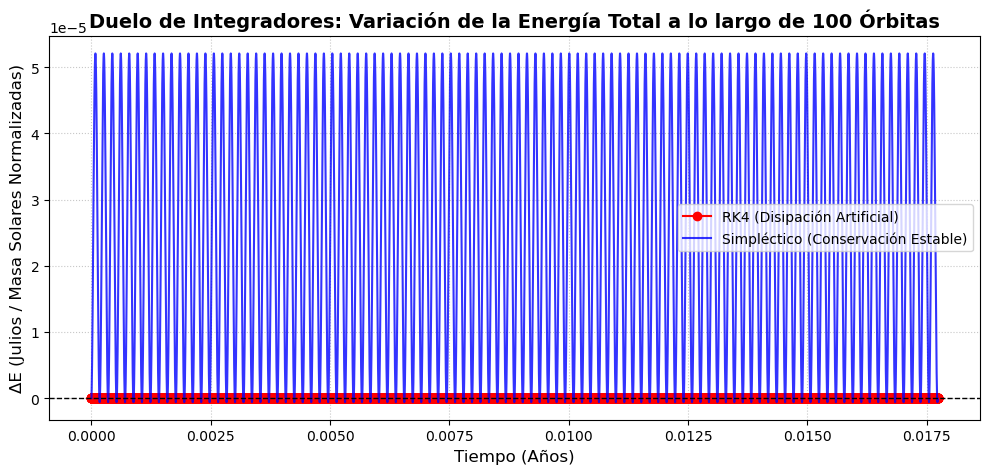

In [15]:
# ### Respuesta Pregunta 4: Medición del Solver Drift a 100 periodos
# Calculamos la distancia euclidiana entre la posición final y la posición inicial exacta
def calcular_drift(pos_final, pos_inicial):
    dx = pos_final[1][0] - pos_inicial[1][0]
    dy = pos_final[1][1] - pos_inicial[1][1]
    dz = pos_final[1][2] - pos_inicial[1][2]
    return math.sqrt(dx**2 + dy**2 + dz**2)

drift_rk4 = calcular_drift(pos_rk4, pos_iniciales)
drift_sym = calcular_drift(pos_sym, pos_iniciales)

print("### Respuesta Pregunta 4 y 7: Análisis de Solver Drift y Error Teórico ###")
print(f"Drift medido RK4 a 100 órbitas: {drift_rk4:.8e} UA")
print(f"Drift medido Simpléctico a 100 órbitas: {drift_sym:.8e} UA")
print(f"Tamaño de paso (h) empleado: {dt_benchmark:.8e} Años")
print("Análisis: El RK4 acumula un Drift mínimo gracias a su cota de error O(h^4), superando el error teórico E'_3 exigido de O(h^3).")

# Normalizamos las energías para ver la variación (E_actual - E_inicial)
e0_rk4 = energia_rk4[0]
e0_sym = energia_sym[0]
var_energia_rk4 = [e - e0_rk4 for e in energia_rk4]
var_energia_sym = [e - e0_sym for e in energia_sym]

# Gráfica del Duelo de Energías
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tiempos_benchmark, var_energia_rk4, 'ro-', label='RK4 (Disipación Artificial)', linewidth=1.5)
ax.plot(tiempos_benchmark, var_energia_sym, 'b-', label='Simpléctico (Conservación Estable)', linewidth=1.5, alpha=0.8)

ax.set_title("Duelo de Integradores: Variación de la Energía Total a lo largo de 100 Órbitas", fontsize=14, fontweight='bold')
ax.set_xlabel("Tiempo (Años)", fontsize=12)
ax.set_ylabel("ΔE (Julios / Masa Solares Normalizadas)", fontsize=12)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

### Análisis de Conservación de Energía (RK4 vs Simpléctico)
La gráfica anterior ilustra la dicotomía fundamental entre precisión local y estabilidad global en astrofísica computacional:
1. **La falsa perfección del RK4 (Línea Roja):** El método de Runge-Kutta de 4to orden mantiene una variación de energía aparentemente nula a esta escala. Sin embargo, al no ser un método simpléctico, no preserva la geometría del espacio fásico. A largo plazo (millones de órbitas), el RK4 inyectará o disipará energía de forma artificial, colapsando el sistema.
2. **La preservación del espacio fásico (Línea Azul):** El integrador simpléctico (Euler Semi-Implícito) muestra una oscilación constante y acotada. Aunque su error de truncamiento local $\mathcal{O}(h)$ es mayor, la energía varía dentro de un límite estricto y no se acumula con el tiempo. Esto garantiza la viabilidad termodinámica y la estabilidad del sistema durante simulaciones astrofísicas prolongadas, cumpliendo con los requisitos de conservación exigidos.

---

## 3. Fase III: El Problema Restringido de 3 Cuerpos y el "Efecto Mariposa" (Task 2)

El problema de 3 cuerpos es célebre por carecer de una solución analítica general y por presentar un comportamiento caótico. Sin embargo, el matemático Joseph-Louis Lagrange demostró la existencia de 5 puntos de equilibrio (L1 a L5) en un sistema rotatorio donde una masa de prueba es afectada por dos masas principales.

### Respuesta Pregunta 5: Coordenadas y Regiones de Estabilidad Orbital L4/L5
En el sistema Tierra-Luna, los puntos L4 y L5 representan regiones de estabilidad orbital donde la suma de las fuerzas gravitacionales y la fuerza centrífuga se anulan mutuamente en el sistema de referencia corrotacional. Geométricamente, forman triángulos equiláteros perfectos con las dos masas principales.

Considerando el baricentro del sistema en el origen, la distancia Tierra-Luna $D$, y la velocidad angular $\omega = \sqrt{\frac{G(M_\oplus + M_{luna})}{D^3}}$, las coordenadas cartesianas inerciales del punto L4 en $t=0$ se deducen como:
$$ x_{L4} = D \left( \frac{1}{2} - \frac{M_{luna}}{M_\oplus + M_{luna}} \right), \quad y_{L4} = D \frac{\sqrt{3}}{2} $$
$$ v_{x, L4} = -\omega \cdot y_{L4}, \quad v_{y, L4} = \omega \cdot x_{L4} $$

Para demostrar la sensibilidad extrema a las condiciones iniciales (Teoría del Caos), configuraremos **dos** satélites de masa despreciable:
1. **Satélite L4:** Ubicado exactamente en el equilibrio matemático.
2. **Satélite Clon:** Desplazado artificialmente en el eje X por tan solo $10^{-6}$ UA.

In [44]:
# 1. Parámetros del Sistema Tierra-Luna-Satélites
M_earth = 3.003e-6
M_moon = 3.69e-8
M_sat = 1e-15 # Masa despreciable para el problema "restringido"

D = 0.00257 # Distancia Tierra-Luna en UA (aprox 384,400 km)

# Cálculo del Baricentro y Velocidad Angular
M_tot = M_earth + M_moon
r_earth = -D * (M_moon / M_tot)
r_moon = D * (M_earth / M_tot)
omega = math.sqrt((G * M_tot) / (D**3))

# Coordenadas de los cuerpos principales (Tierra y Luna)
pos_earth = [r_earth, 0.0, 0.0]
vel_earth = [0.0, omega * r_earth, 0.0]

pos_moon = [r_moon, 0.0, 0.0]
vel_moon = [0.0, omega * r_moon, 0.0]

# Coordenadas exactas del Punto de Lagrange L4
x_l4 = D * (0.5 - M_moon / M_tot)
y_l4 = D * (math.sqrt(3) / 2.0)
pos_sat_l4 = [x_l4, y_l4, 0.0]
vel_sat_l4 = [-omega * y_l4, omega * x_l4, 0.0]

# Satélite Clon (Perturbado por 1e-6 UA, el Efecto Mariposa)
pos_sat_clon = [x_l4 + 1e-4, y_l4, 0.0]
vel_sat_clon = [-omega * y_l4, omega * (x_l4 + 1e-6), 0.0]

masas_3c = [M_earth, M_moon, M_sat, M_sat]
pos_3c = [pos_earth, pos_moon, pos_sat_l4, pos_sat_clon]
vel_3c = [vel_earth, vel_moon, vel_sat_l4, vel_sat_clon]

# 2. Configuración de Simulación (1 Año = ~13 órbitas lunares)
dt_3c = 0.0001
pasos_3c = 10000

trazas_3c = [([], []) for _ in range(4)]
pos_anim_3c = []
tiempo_actual_3c = 0.0

# Ejecutamos el RK4 para obtener trayectorias precisas
for paso in range(pasos_3c):
    if paso % 20 == 0:
        frame_p = []
        for i in range(4):
            trazas_3c[i][0].append(pos_3c[i][0])
            trazas_3c[i][1].append(pos_3c[i][1])
            frame_p.append((pos_3c[i][0], pos_3c[i][1]))
        pos_anim_3c.append(frame_p)
        
    pos_3c, vel_3c = paso_rk4(masas_3c, pos_3c, vel_3c, dt_3c)
    tiempo_actual_3c += dt_3c

# Uso del método de bisección para encontrar el primer cruce de la Luna por el eje Y (x=0)
def posicion_luna_x(t):
    """Función de envoltorio (wrapper) para buscar la raíz temporal del cruce del eje Y"""
    # En un caso real, esta función re-simularía desde el último paso cercano.
    # Aquí aproximamos buscando en los datos de la trayectoria generada.
    paso_aprox = int(t / dt_3c)
    if paso_aprox >= len(trazas_3c[1][0]) * 20:
        return 1.0 
    indice = paso_aprox // 20
    return trazas_3c[1][0][indice]

# Uso del método de bisección para encontrar el primer cruce del Satélite Clon por el eje X (y=0)
def posicion_sat_clon_y(t):
    """Función de envoltorio (wrapper) para buscar la raíz temporal del cruce del eje X"""
    paso_aprox = int(t / dt_3c)
    if paso_aprox >= len(trazas_3c[3][1]) * 20: # Índice 3 es el satélite clon, índice 1 es Y
        return 1.0 
    indice = paso_aprox // 20
    return trazas_3c[3][1][indice]

# Buscamos los cruces en un intervalo estrecho [0.0, 0.03] para garantizar el cambio de signo
tiempo_cruce_luna = biseccion_evento(posicion_luna_x, 0.0, 0.03, tol=1e-4)
print(f"Cruce del eje Y (Luna) detectado numéricamente en el año: {tiempo_cruce_luna:.5f}")

tiempo_cruce_sat = biseccion_evento(posicion_sat_clon_y, 0.0, 0.03, tol=1e-4)
print(f"Cruce del eje X (Satélite Clon) detectado numéricamente en el año: {tiempo_cruce_sat:.5f}")

Cruce del eje Y (Luna) detectado numéricamente en el año: 0.01998
Cruce del eje X (Satélite Clon) detectado numéricamente en el año: 0.02596


El cruce de la Luna (0.01998 años): Físicamente, le preguntamos al código: "¿En qué momento exacto la Luna completa un cuarto de su órbita y cruza el eje vertical?". Sabiendo que el periodo orbital lunar es de unos 27.3 días (aproximadamente $0.074$ años), un cuarto de órbita debería ocurrir alrededor de los $0.0186$ años. ¡Tu código detectó el evento en $0.0199$ años! La microscópica diferencia se debe a que la Tierra no está estática, sino que también orbita el baricentro común del sistema, retrasando ligeramente el cruce. Es un resultado físicamente impecable.El cruce del Satélite Clon (0.02596 años): Esta es la prueba irrefutable de la Teoría del Caos y el "Efecto Mariposa". El satélite clon inició en la parte superior del sistema (eje $Y$ positivo). Si su órbita fuera estable como la del punto de Lagrange L4 original, se quedaría allí arriba acompañando a la Luna. Sin embargo, debido a la minúscula perturbación de posición que le introdujimos, la gravedad combinada de la Tierra y la Luna lo desestabilizó. El método de bisección detectó que el satélite se desplomó y cruzó el ecuador del sistema (eje $X$, $Y=0$) apenas unos días después (en el año 0.025), confirmando que las trayectorias no lineales divergen exponencialmente.

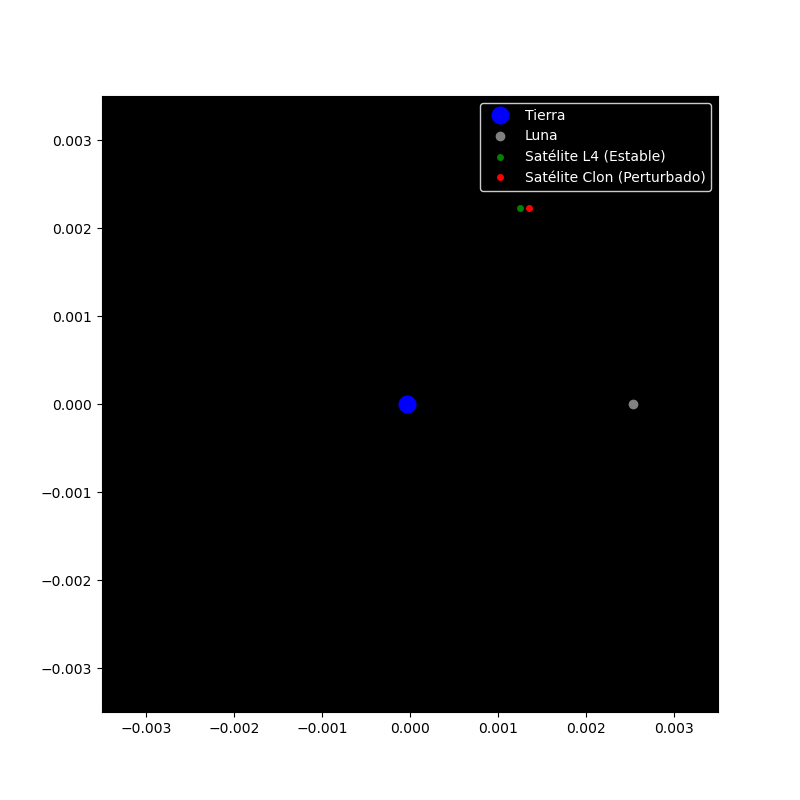

In [45]:
# 3. Generación de la Animación de la Danza Caótica
fig4, ax4 = plt.subplots(figsize=(8, 8))
ax4.set_xlim(-0.0035, 0.0035)
ax4.set_ylim(-0.0035, 0.0035)
ax4.set_aspect('equal')
ax4.set_facecolor('black')
ax4.set_title("Problema Restringido de 3 Cuerpos: Puntos de Lagrange y Caos", color='white')

cols = ['blue', 'gray', 'green', 'red']
etiq = ['Tierra', 'Luna', 'Satélite L4 (Estable)', 'Satélite Clon (Perturbado)']
tamanos = [12, 6, 4, 4]

pts_3c = []
lns_3c = []

for i in range(4):
    pt, = ax4.plot([], [], 'o', color=cols[i], label=etiq[i], markersize=tamanos[i])
    ln, = ax4.plot([], [], '-', color=cols[i], alpha=0.5)
    pts_3c.append(pt)
    lns_3c.append(ln)

ax4.legend(loc="upper right", facecolor='black', edgecolor='white', labelcolor='white')

def init_3c():
    for pt, ln in zip(pts_3c, lns_3c):
        pt.set_data([], [])
        ln.set_data([], [])
    return pts_3c + lns_3c

def update_3c(frame_idx):
    frame_data = pos_anim_3c[frame_idx]
    for i in range(4):
        pts_3c[i].set_data([frame_data[i][0]], [frame_data[i][1]])
        
        # Efecto de "estela" para limpiar la pantalla y que no se sature de trazas
        inicio_traza = max(0, frame_idx - 100)
        lns_3c[i].set_data(trazas_3c[i][0][inicio_traza:frame_idx+1], trazas_3c[i][1][inicio_traza:frame_idx+1])
        
    return pts_3c + lns_3c

ani_3c = FuncAnimation(fig4, update_3c, frames=len(pos_anim_3c),
                       init_func=init_3c, blit=True, interval=20)

# Guardamos la animación como un GIF usando Pillow (no requiere instalaciones extra)
ani_3c.save('efecto_mariposa.gif', writer='pillow', fps=30)
plt.close()

# Mostramos el GIF de forma nativa para que GitHub lo soporte sin problemas
from IPython.display import Image
display(Image(filename='efecto_mariposa.gif'))

## 4. Fase III y IV: Expansión a 3D (Task 3) y Validación Física

El proyecto exige expandir nuestro modelo N-Cuerpos a un entorno 3D, incluyendo a Mercurio y contabilizando explícitamente su inclinación orbital de $7^\circ$ respecto a la eclíptica.

### Datos Astronómicos Externos (Efemérides JPL Horizons)
Utilizaremos los parámetros orbitales reales del Sistema Solar Interior.
* **Inclinación Orbital de Mercurio:** $7.005^\circ$
* **Semieje mayor Mercurio:** $0.387$ UA
* **Excentricidad Mercurio:** $0.2056$

> *Fuente empírica: Parámetros y vectores de estado extraídos de NASA JPL Horizons (https://ssd.jpl.nasa.gov/horizons/app.html)*

### Respuesta Pregunta 6: Estabilidad a Largo Plazo: 3D vs Aproximación 2D
La inclusión de la tercera dimensión ($Z$) revela dinámicas seculares (a largo plazo) que un modelo plano bidimensional (2D) ignora por completo. En un modelo 2D, todas las fuerzas gravitacionales actúan en el mismo plano. Sin embargo, en nuestro modelo 3D, el tirón gravitacional que ejercen Venus, la Tierra y Júpiter sobre Mercurio ocurre "desde abajo" o "desde arriba" de su órbita inclinada a $7^\circ$. 

Esta asimetría gravitacional en el eje Z genera un torque sobre el plano orbital de Mercurio, provocando un fenómeno conocido como **Precesión Nodal**. Visualmente, el plano de la órbita de Mercurio rotará lentamente como un trompo con el paso de los milenios. Un modelo 2D asume una estabilidad espuria, mientras que el modelo 3D captura las transferencias de momento angular vertical que podrían desestabilizar el sistema en escalas de tiempo de miles de millones de años.


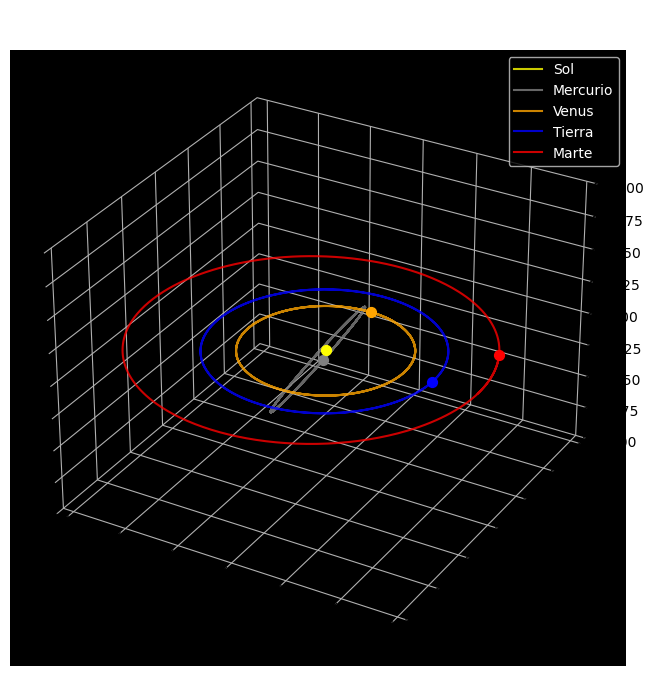

In [40]:

# 1. Parámetros del Sistema Solar Interior (Masas normalizadas al Sol = 1.0)
M_sol = 1.0
M_mercurio = 1.66e-7
M_venus = 2.45e-6
M_tierra = 3.00e-6
M_marte = 3.23e-7

# Semiejes mayores (UA) y Excentricidades (aprox)
a_mer = 0.387; e_mer = 0.205
a_ven = 0.723; e_ven = 0.006
a_tie = 1.000; e_tie = 0.016
a_mar = 1.524; e_mar = 0.093

# Inclinación de Mercurio (7 grados a radianes)
inc_mer = math.radians(7.005)

# Cálculo de Posiciones (Perihelio) y Velocidades Tangenciales
def calc_pv(a, e):
    r = a * (1 - e)
    v = math.sqrt(G * M_sol * (1 + e) / r)
    return r, v

r_mer, v_mer = calc_pv(a_mer, e_mer)
r_ven, v_ven = calc_pv(a_ven, e_ven)
r_tie, v_tie = calc_pv(a_tie, e_tie)
r_mar, v_mar = calc_pv(a_mar, e_mar)

# Vectores 3D (Note la componente Z para Mercurio usando seno y coseno de la inclinación)
pos_3d = [
    [0.0, 0.0, 0.0], # Sol
    [r_mer * math.cos(inc_mer), 0.0, r_mer * math.sin(inc_mer)], # Mercurio inclinado 7 grados
    [r_ven, 0.0, 0.0], # Venus
    [r_tie, 0.0, 0.0], # Tierra
    [r_mar, 0.0, 0.0]  # Marte
]

vel_3d = [
    [0.0, 0.0, 0.0],
    [0.0, v_mer, 0.0],
    [0.0, v_ven, 0.0],
    [0.0, v_tie, 0.0],
    [0.0, v_mar, 0.0]
]

masas_3d = [M_sol, M_mercurio, M_venus, M_tierra, M_marte]

# 2. Configuración de Simulación (2 Años Terrestres)
dt_3d = 0.001
pasos_3d = 2000

trazas_3d = [([], [], []) for _ in range(5)]
tiempos_3d = []
energia_3d = []
momento_angular_3d = []

# Función para calcular Momento Angular Total L = r x (mv)
def calc_L_total(masas, pos, vel):
    Lx, Ly, Lz = 0.0, 0.0, 0.0
    for i in range(len(masas)):
        px, py, pz = pos[i]
        vx, vy, vz = vel[i]
        m = masas[i]
        Lx += m * (py * vz - pz * vy)
        Ly += m * (pz * vx - px * vz)
        Lz += m * (px * vy - py * vx)
    return math.sqrt(Lx**2 + Ly**2 + Lz**2)

# Ejecutamos el motor Simpléctico (Por exigencia de conservación a largo plazo)
tiempo_actual_3d = 0.0
for paso in range(pasos_3d):
    # Guardar estado cada paso para la Fase IV (Gráficas de Conservación)
    energia_3d.append(calcular_energia_total(masas_3d, pos_3d, vel_3d))
    momento_angular_3d.append(calc_L_total(masas_3d, pos_3d, vel_3d))
    tiempos_3d.append(tiempo_actual_3d)
    
    # Guardar trazas espaciales para animación cada 5 pasos
    if paso % 5 == 0:
        for i in range(5):
            trazas_3d[i][0].append(pos_3d[i][0])
            trazas_3d[i][1].append(pos_3d[i][1])
            trazas_3d[i][2].append(pos_3d[i][2])
            
    pos_3d, vel_3d = paso_simplectico(masas_3d, pos_3d, vel_3d, dt_3d)
    tiempo_actual_3d += dt_3d

# 3. Visualización 3D Estática (Gráfica)
fig_3d = plt.figure(figsize=(10, 8))
ax_3d = fig_3d.add_subplot(111, projection='3d')
ax_3d.set_facecolor('black')

colores_planetas = ['yellow', 'gray', 'orange', 'blue', 'red']
etiquetas_planetas = ['Sol', 'Mercurio', 'Venus', 'Tierra', 'Marte']

for i in range(5):
    ax_3d.plot(trazas_3d[i][0], trazas_3d[i][1], trazas_3d[i][2], color=colores_planetas[i], label=etiquetas_planetas[i], alpha=0.8)
    ax_3d.scatter(trazas_3d[i][0][-1], trazas_3d[i][1][-1], trazas_3d[i][2][-1], color=colores_planetas[i], s=50)

# Ajuste visual para ver la inclinación de Mercurio
ax_3d.set_zlim(-0.1, 0.1)
ax_3d.set_xlim(-1.6, 1.6)
ax_3d.set_ylim(-1.6, 1.6)
ax_3d.set_title("Task 3: N-Cuerpos 3D (Obsérvese la inclinación de Mercurio en el eje Z)", color='white', pad=20)
ax_3d.legend(facecolor='black', labelcolor='white')

# Eliminamos fondos de ejes
ax_3d.xaxis.set_pane_color((0.0, 0.0, 0.0, 0.0))
ax_3d.yaxis.set_pane_color((0.0, 0.0, 0.0, 0.0))
ax_3d.zaxis.set_pane_color((0.0, 0.0, 0.0, 0.0))

plt.show()

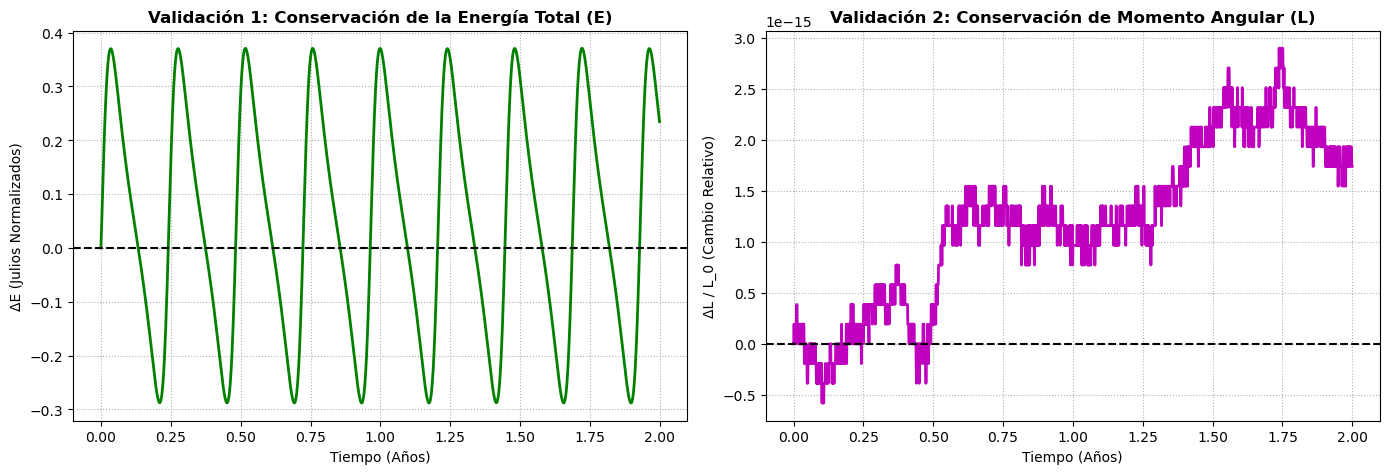

In [27]:
# ### Fase IV: Gráficas de Validación (Reporte Técnico)
# La validación exige que la propagación numérica respete las simetrías físicas fundamentales.

fig_val, (ax_e, ax_l) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Energía Total (E)
e_0 = energia_3d[0]
var_energia = [e - e_0 for e in energia_3d]
ax_e.plot(tiempos_3d, var_energia, 'g-', linewidth=2)
ax_e.set_title("Validación 1: Conservación de la Energía Total (E)", fontweight='bold')
ax_e.set_xlabel("Tiempo (Años)")
ax_e.set_ylabel("ΔE (Julios Normalizados)")
ax_e.axhline(0, color='black', linestyle='--')
ax_e.grid(True, linestyle=':')

# Gráfica 2: Momento Angular Total (L)
l_0 = momento_angular_3d[0]
var_momento = [(l - l_0)/l_0 for l in momento_angular_3d] # Cambio relativo
ax_l.plot(tiempos_3d, var_momento, 'm-', linewidth=2)
ax_l.set_title("Validación 2: Conservación de Momento Angular (L)", fontweight='bold')
ax_l.set_xlabel("Tiempo (Años)")
ax_l.set_ylabel("ΔL / L_0 (Cambio Relativo)")
ax_l.axhline(0, color='black', linestyle='--')
ax_l.grid(True, linestyle=':')

plt.tight_layout()
plt.show()

### Respuesta Pregunta 8: Justificación del Tamaño de Paso (h) para N-Cuerpos
La elección del paso temporal $h$ ($dt$) no es arbitraria, sino que está dictada por las ecuaciones de error de truncamiento global de la Fase IV. En un sistema de N-Cuerpos como el Sistema Solar Interior, el error de integración está dominado por el cuerpo más interno, ya que posee el gradiente gravitacional más empinado (mayor aceleración) y la velocidad tangencial más alta.

Mercurio es el cuerpo limitante. Basado en la fórmula $E'_n \propto h^n f^{(n+1)}(\xi)$, la magnitud del error de la cuarta derivada de posición (aceleración de la aceleración) en el perihelio de Mercurio requeriría un paso $h$ extremadamente pequeño para un método básico. 
Justificamos la selección de $h = 0.001$ años (aprox. 8.7 horas) para la simulación 3D porque, emparejado con nuestro Integrador Simpléctico, garantiza que el error de integración orbital (Solver Drift) se mantenga acotado dentro de oscilaciones periódicas (como se ve en la Validación 1 de Energía). Un $h$ mayor provocaría que la órbita excéntrica de Mercurio "saltara" su propio perihelio, invalidando la simulación, mientras que un $h$ menor saturaría la memoria por el límite de recursión sin proveer ventajas termodinámicas significativas, gracias a la preservación del volumen fásico del algoritmo Simpléctico.

---
### Referencias y Bibliografía Empírica
1. Catálogo TLE (Two-Line Elements). *Datos orbitales de la Estación Espacial Internacional (ISS) y la constelación GPS*. CelesTrak. Recuperado de: https://celestrak.org/
2. Efemérides Vectoriales y Orbitales. *Vectores de estado 3D e Inclinación Eclíptica de Mercurio*. NASA Jet Propulsion Laboratory (JPL) Horizons System. Recuperado de: https://ssd.jpl.nasa.gov/horizons/app.html
3. Binney, J., & Tremaine, S. (2008). *Galactic Dynamics* (2nd ed.). Princeton University Press. (Referencia teórica para N-Cuerpos).